# 06 · Ajuste de hiperparámetros

**Objetivo:** encontrar, para cada red (RNN simple, LSTM y GRU) y cada horizonte (5, 63 y 252 días hábiles), la configuración que mejor predice, en **condiciones idénticas** para las tres y validando siempre en años que la red no ha visto. La ventana de entrada se elige **a la vez para las tres redes**, como pide el enunciado.

Este notebook **no entrena nada**: lee los resultados de

```bash
poetry run python scripts/tune.py --all      # 18 búsquedas: 3 redes × 3 horizontes × 2 ventanas
```

guardados en `reports/tuning/ronda_5/`: `*_trials.csv` (todos los intentos), `*_best.json` (la mejor configuración) y `ventana_decision.json` (la ventana elegida).

**Contenido**
1. Cómo funciona cada red por dentro
2. Las reglas: condiciones iguales para las tres
3. Qué ventana de entrada usar
4. Evolución de la búsqueda
5. Configuraciones ganadoras y su arquitectura
6. Resultado por año de validación
7. ¿Qué hiperparámetros funcionan?
8. Conclusiones

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import NullFormatter

from oil_forecast.config import HORIZONS, N_TRIALS, study_name, tuning_dir
from oil_forecast.models import CELLS
from oil_forecast.plotting import (
    CELL_NAMES,
    COLORS,
    draw_architecture,
    draw_cell,
    set_style,
)

set_style()
pd.set_option("display.float_format", "{:.3f}".format)
ROUND = 5  # search used by the final model
TUNING_DIR = tuning_dir(ROUND)
NETS = list(CELL_NAMES.values())
decision = json.loads((TUNING_DIR / "ventana_decision.json").read_text())
WINDOWS = sorted({int(w) for d in decision["horizontes"].values() for w in d["puntuaciones"]})
CHOSEN = {hname: decision["horizontes"][str(h)]["ventana"] for hname, h in HORIZONS.items()}

trials, best = [], {}
for cell in CELLS:
    for hname, h in HORIZONS.items():
        for w in WINDOWS:
            name = study_name(cell, h, w)
            t = pd.read_csv(TUNING_DIR / f"{name}_trials.csv")
            t["celda"], t["red"], t["horizonte"], t["ventana"] = cell, CELL_NAMES[cell], hname, w
            trials.append(t)
            best[(CELL_NAMES[cell], hname, w)] = json.loads((TUNING_DIR / f"{name}_best.json").read_text())
trials = pd.concat(trials, ignore_index=True)
YEARS = sorted(c.replace("user_attrs_rel_rmse_", "") for c in trials.columns if c.startswith("user_attrs_rel_rmse_"))
print(f"{len(trials)} intentos en {len(best)} búsquedas · {N_TRIALS[ROUND]} intentos por búsqueda · ventanas {WINDOWS}")

540 intentos en 18 búsquedas · 30 intentos por búsqueda · ventanas [20, 60]


## 1. Cómo funciona cada red por dentro

Las tres redes leen la secuencia de días de entrada **uno a uno** y van actualizando un **estado oculto** *h* que resume lo visto hasta ese momento. La diferencia está en *cómo* actualizan ese estado:

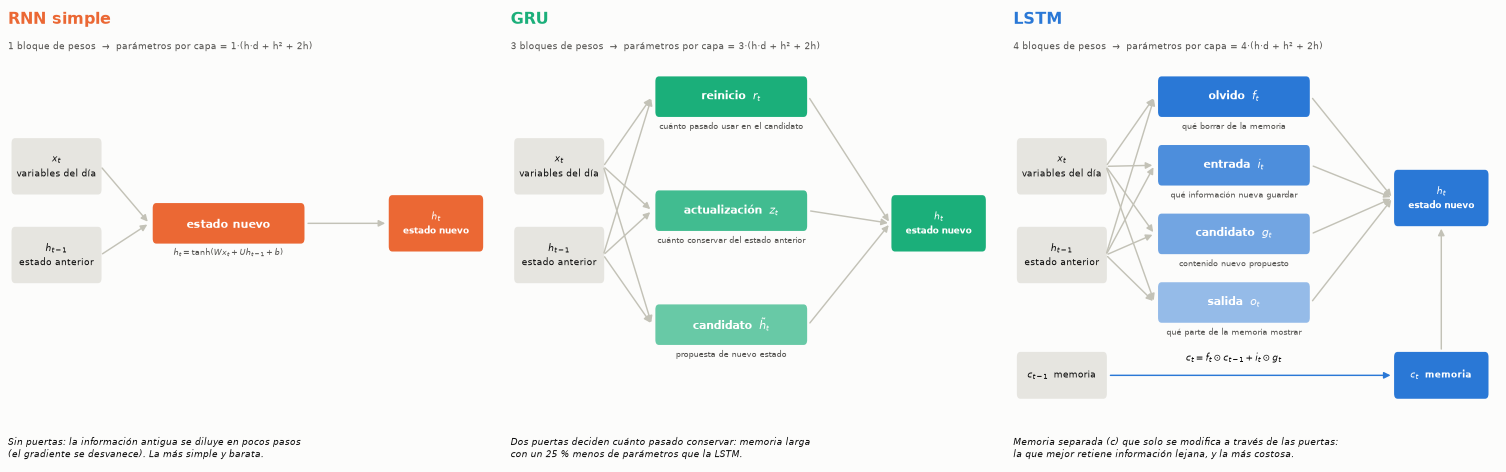

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, cell in zip(axes, ["rnn", "gru", "lstm"]):
    draw_cell(ax, cell)
plt.tight_layout()

- La **RNN simple** mezcla la entrada y el estado anterior en una sola operación. Es barata, pero al repetir esa operación muchas veces la información de los primeros días se va borrando.
- La **GRU** añade dos **puertas** (pequeñas redes con salida entre 0 y 1) que deciden cuánto del estado anterior se conserva y cuánto se sustituye.
- La **LSTM** tiene además una **memoria separada** (*c*) por la que la información puede viajar muchos pasos casi sin alterarse; tres puertas controlan qué se borra, qué se añade y qué se muestra.

Con el mismo tamaño de capa, la GRU tiene unas **3 veces** los parámetros de la RNN y la LSTM **4 veces**. Más memoria también significa más riesgo de memorizar ruido con pocos datos, así que no está claro de antemano cuál ganará.

## 2. Las reglas: condiciones iguales para las tres

| Elemento | Valor (igual para RNN, LSTM y GRU) |
|---|---|
| Datos | 16 variables (notebook 03); ventana de entrada de **20 o 60 días**, común a las tres redes (apartado 3) |
| Objetivo | retorno logarítmico a *h* días, estandarizado con el train; la predicción no arrastra la subida media del periodo de entrenamiento |
| Arquitectura | capa(s) recurrente(s) → dropout → capa lineal sobre el último estado oculto (**solo cambia la celda**) |
| Validación | walk-forward con ventana de entrenamiento creciente, un bloque por año (2019-2023) y **embargo de *h* días** |
| Parada temprana | último 15 % del train de cada bloque (con embargo); **nunca** el año que se evalúa |
| Optimizador | Adam, recorte del gradiente a norma 1, máximo 150 épocas, paciencia 15 |
| Espacio de búsqueda | neuronas {16, 32, 64} · capas {1, 2} · dropout [0, 0,5] · *learning rate* [3·10⁻⁵, 10⁻³] · lote {64, 128, 256} · *weight decay* [10⁻⁶, 10⁻³] · pérdida {MSE, Huber} |
| Presupuesto | **30 intentos** por red, horizonte y ventana; muestreador TPE con la misma semilla y el mismo primer intento |
| Semillas | **2 por intento** (se promedia su predicción), para que el azar de la inicialización pese menos en la elección |
| Poda | un intento se abandona si tras sus primeros años va peor que la mediana de los anteriores |
| Métrica | media por año de **RMSE(red) / RMSE(ingenuo)**, con precios en dólares |
| Hardware | CPU, 1 hilo por modelo |

**Cómo leer la métrica:** 1,00 es igual que suponer que el precio no cambia; 0,95 es un 5 % menos de error; 1,10, un 10 % más. Se divide por el ingenuo **de cada año** para que los años muy volátiles (2020, 2022) no dominen la media.

**¿Qué es un intento?** Optuna propone una configuración, se entrena la red con cada año de validación (hasta 5 entrenamientos por semilla) y se anota el error medio. Con lo aprendido de los intentos anteriores propone el siguiente, concentrándose en las zonas prometedoras.

## 3. Qué ventana de entrada usar

El enunciado pide **la misma ventana para las tres redes**. Por eso no se elige red a red: se hace la búsqueda completa con 20 y con 60 días y se aplica una regla fijada de antemano.

> **Regla:** por horizonte, para cada ventana se calcula la media de las tres redes de la media de sus 5 mejores intentos. Gana la menor; si la diferencia es menor de 0,01, gana la ventana más corta (se entrena unas tres veces más rápido y tiene menos parámetros de entrada).

In [3]:
rows = []
for hname, h in HORIZONS.items():
    for w, s in decision["horizontes"][str(h)]["puntuaciones"].items():
        rows.append({"horizonte": hname, "ventana": f"{w} días", **{CELL_NAMES[c]: s[c] for c in CELLS},
                     "media 3 redes": s["media_3_redes"], "elegida": "✓" if int(w) == CHOSEN[hname] else ""})
window_table = pd.DataFrame(rows).set_index(["horizonte", "ventana"])
(window_table.style.format({c: "{:.3f}" for c in [*NETS, "media 3 redes"]})
 .background_gradient(subset=[*NETS, "media 3 redes"], cmap="RdYlGn_r", vmin=0.9, vmax=1.1))

**Resultado: 20 días en los tres horizontes.** A 1 semana y a 3 meses las dos ventanas empatan (diferencias de 0,001 y 0,0002). A 1 año, la de 60 días queda 0,009 por delante, por debajo del umbral de 0,01. Mirar 60 días atrás no aporta nada claro, y con 20 días cada entrenamiento es entre 2 y 5 veces más rápido. El resto del notebook muestra la búsqueda con la ventana elegida.

In [4]:
sel = trials[trials.ventana == trials.horizonte.map(CHOSEN)].copy()
sel_best = {(r, h): best[(r, h, CHOSEN[h])] for r in NETS for h in HORIZONS}
counts = sel.groupby(["horizonte", "red"]).state.value_counts().unstack(fill_value=0).loc[list(HORIZONS)]
counts.rename(columns={"COMPLETE": "completos", "PRUNED": "podados"})

state                 completos  podados
horizonte red                           
corto     GRU                29        1
          LSTM               21        9
          RNN simple         21        9
medio     GRU                25        5
          LSTM               29        1
          RNN simple         27        3
largo     GRU                16       14
          LSTM               22        8
          RNN simple         24        6

## 4. Evolución de la búsqueda

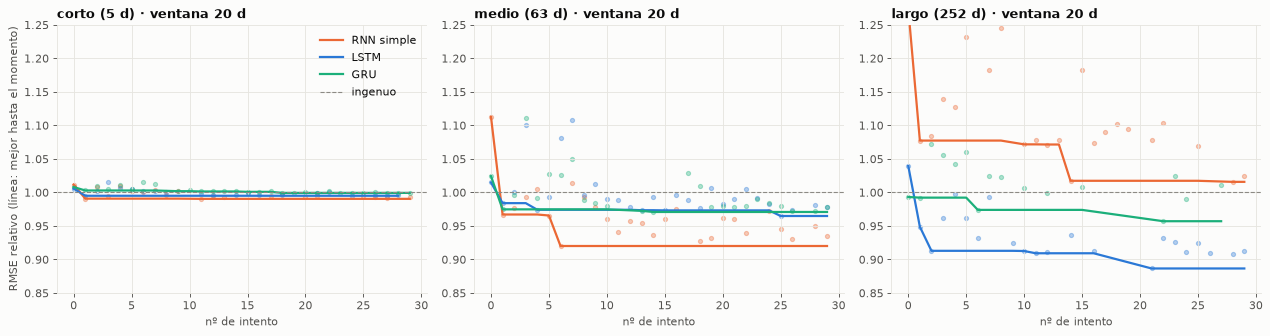

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, hname in zip(axes, HORIZONS):
    for red in NETS:
        t = sel[(sel.horizonte == hname) & (sel.red == red)].sort_values("number")
        done = t[t.state == "COMPLETE"]
        ax.scatter(done["number"], done["value"], s=14, color=COLORS[red], alpha=0.35)
        ax.plot(done["number"], done["value"].cummin(), color=COLORS[red], label=red)
    ax.axhline(1, color=COLORS["Ingenuo"], ls="--", lw=1, label="ingenuo")
    ax.set_title(f"{hname} ({HORIZONS[hname]} d) · ventana {CHOSEN[hname]} d"); ax.set_xlabel("nº de intento")
    ax.set_ylim(0.85, 1.25)
axes[0].set_ylabel("RMSE relativo (línea: mejor hasta el momento)")
axes[0].legend(loc="upper right")
plt.tight_layout()

**Qué se ve:**
- **1 semana:** las curvas son planas desde el principio. Cualquier red acaba aprendiendo que lo mejor es predecir casi «sin cambio»; la mejor (RNN simple, 0,990) mejora al ingenuo un 1 %.
- **3 meses:** las tres bajan de 1 en pocos intentos. La **RNN simple** es la mejor con diferencia (**0,920**), por delante de LSTM (0,965) y GRU (0,971).
- **1 año:** la **LSTM** baja hasta **0,887** y la GRU a 0,957; la RNN simple no encuentra ninguna configuración que gane al ingenuo (1,016).

## 5. Configuraciones ganadoras y su arquitectura

In [6]:
rows = []
for (red, hname), b in sel_best.items():
    rows.append({"horizonte": hname, "red": red, "RMSE relativo": b["value"], "intento": b["trial"],
                 "neuronas": b["params"]["hidden_size"], "capas": b["params"]["num_layers"],
                 "dropout": b["params"]["dropout"], "learning rate": b["params"]["lr"],
                 "lote": b["params"]["batch_size"], "weight decay": b["params"]["weight_decay"],
                 "pérdida": b["params"]["loss"], "parámetros": b["user_attrs"]["n_params"],
                 "s por año": b["user_attrs"]["mean_train_time_s"]})
best_table = pd.DataFrame(rows)
best_table["horizonte"] = pd.Categorical(best_table["horizonte"], list(HORIZONS), ordered=True)
best_table = best_table.sort_values(["horizonte", "red"]).set_index(["horizonte", "red"])
(best_table.style.format({"RMSE relativo": "{:.3f}", "dropout": "{:.2f}", "learning rate": "{:.1e}",
                          "weight decay": "{:.1e}", "parámetros": "{:,.0f}", "s por año": "{:.1f}"})
 .background_gradient(subset=["RMSE relativo"], cmap="RdYlGn_r", vmin=0.9, vmax=1.1))

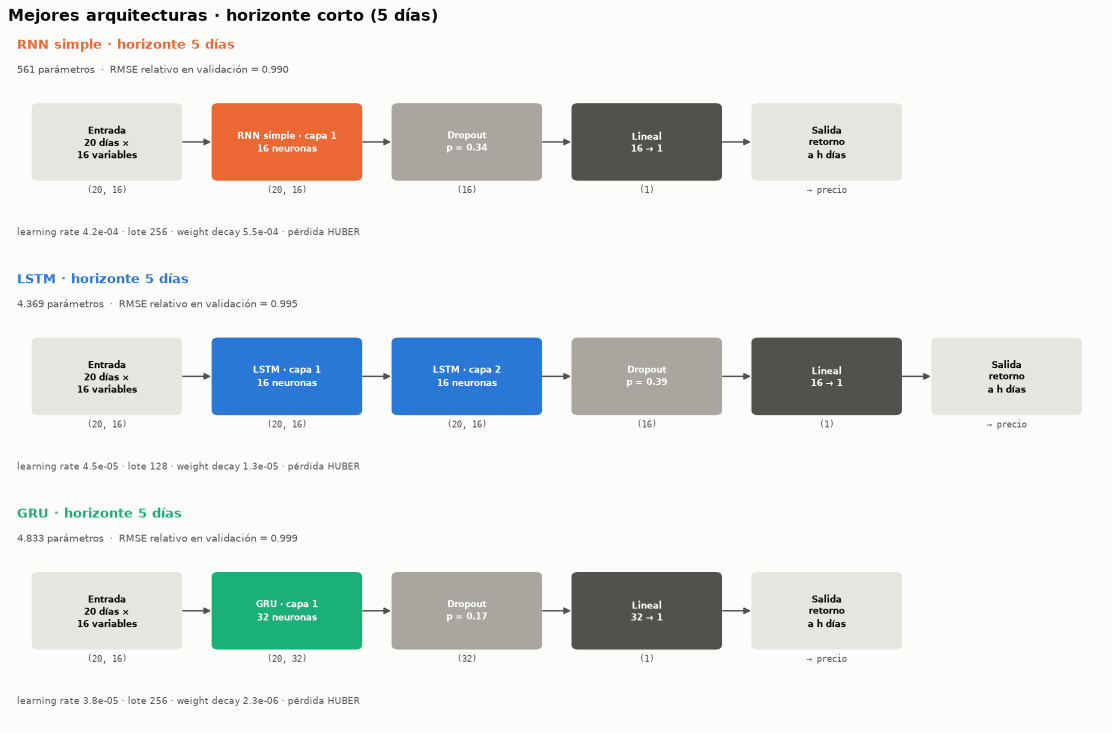

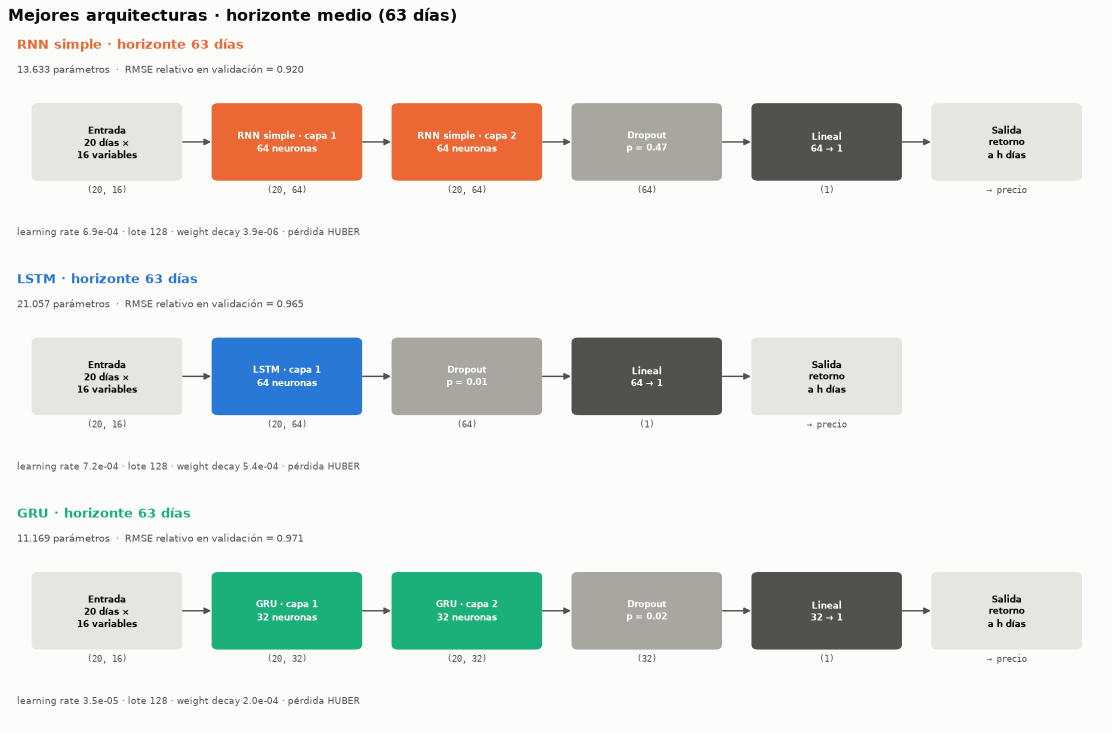

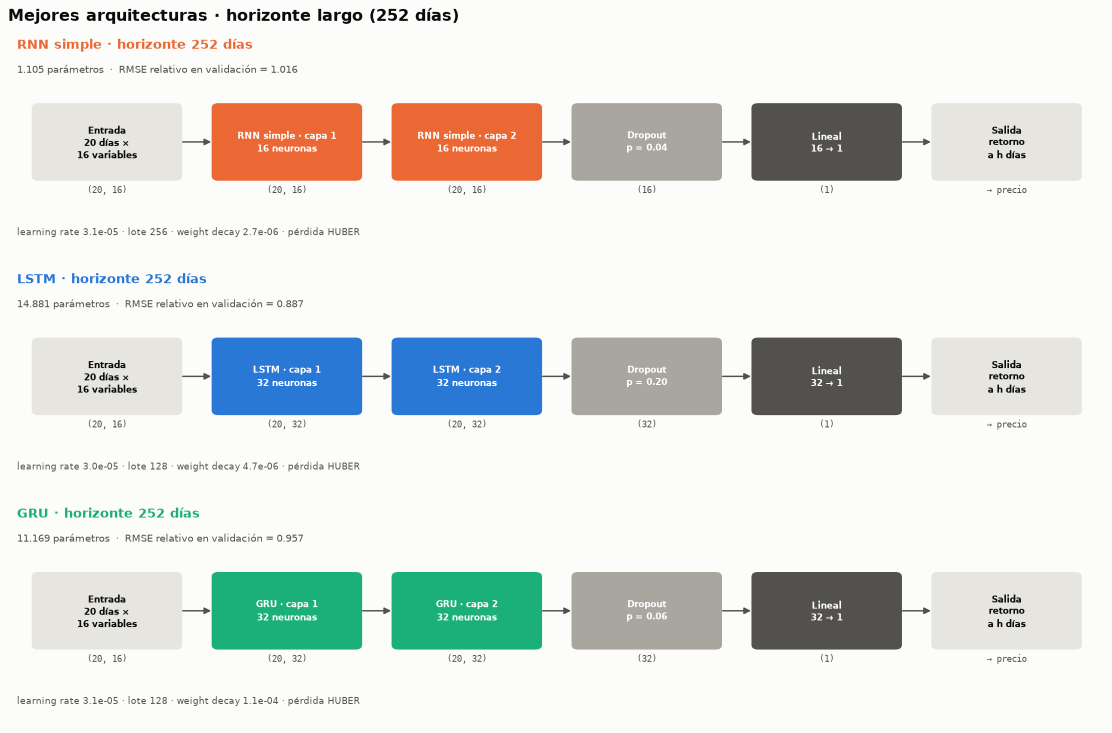

In [7]:
for hname, h in HORIZONS.items():
    fig, axes = plt.subplots(3, 1, figsize=(14, 9.3))
    for ax, cell in zip(axes, CELLS):
        b = sel_best[(CELL_NAMES[cell], hname)]
        draw_architecture(ax, cell, b["params"], b["user_attrs"]["n_params"], window=CHOSEN[hname],
                          horizon=h, score=b["value"])
    fig.suptitle(f"Mejores arquitecturas · horizonte {hname} ({h} días)", x=0.01, ha="left", fontsize=14, weight="bold")
    plt.tight_layout()
    plt.show()

**Patrones de las configuraciones ganadoras:**
- **Pérdida de Huber en 9 de 9.** Es menos sensible a los errores enormes (2020, 2022) y evita que unos pocos días extremos dominen el entrenamiento.
- **Redes pequeñas.** Ninguna ganadora pasa de 21.000 parámetros; a 1 semana gana la RNN más pequeña posible (16 neuronas, 561 parámetros).
- **Aprender despacio.** Seis de las nueve ganadoras usan un *learning rate* cercano al mínimo del rango (3-5·10⁻⁵).
- **Más parámetros no implica mejor resultado:** a 3 meses la RNN simple gana con menos parámetros que la LSTM.

## 6. Resultado por año de validación

Una media puede esconder que un modelo gana mucho un año y pierde otro. Mapa del RMSE relativo de cada configuración ganadora en cada año (verde = mejor que el ingenuo). A 1 año no hay 2023, porque esas predicciones caerían en el periodo de test.

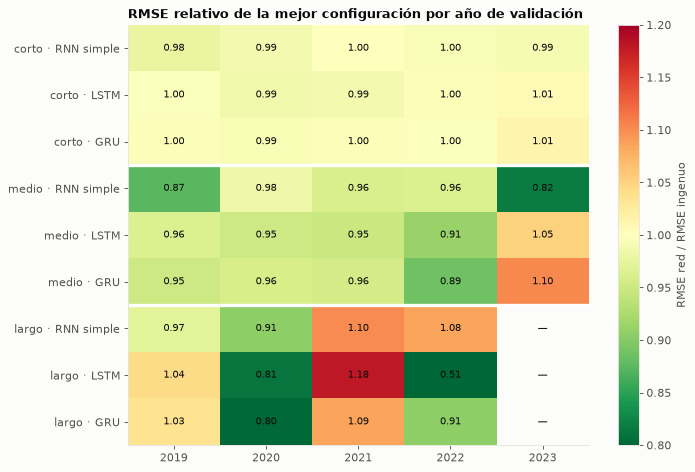

In [8]:
per_year = pd.DataFrame({(red, hname): {k.replace("rel_rmse_", ""): v for k, v in b["user_attrs"].items()
                                         if k.startswith("rel_rmse_")} for (red, hname), b in sel_best.items()}).T
per_year = per_year.loc[[(r, h) for h in HORIZONS for r in NETS]]
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(per_year, cmap="RdYlGn_r", vmin=0.8, vmax=1.2, aspect="auto")
ax.set_xticks(range(per_year.shape[1]), per_year.columns)
ax.set_yticks(range(per_year.shape[0]), [f"{h} · {r}" for r, h in per_year.index])
for i in range(per_year.shape[0]):
    for j in range(per_year.shape[1]):
        v = per_year.iloc[i, j]
        ax.text(j, i, "—" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=9)
for y in (2.5, 5.5):
    ax.axhline(y, color="white", lw=3)
ax.grid(False); fig.colorbar(im, label="RMSE red / RMSE ingenuo")
ax.set_title("RMSE relativo de la mejor configuración por año de validación")
plt.tight_layout()

**Lectura año a año:**
- **1 semana:** todos los años entre 0,98 y 1,01. Sin sorpresas.
- **3 meses:** la **RNN simple gana al ingenuo los 5 años** (0,82-0,98). LSTM y GRU ganan de 2019 a 2022 pero **pierden en 2023** (1,05 y 1,10).
- **1 año:** el resultado depende de pocos episodios. 2020 (tras el desplome de la pandemia, el precio rebota) favorece a todas (0,80-0,91); 2021 perjudica a todas; y en 2022 la LSTM acierta mucho (0,51). Con tan pocos episodios independientes, la diferencia entre redes a un año vista hay que tomarla con mucha cautela; por eso el notebook 08 añade una **validación hacia atrás** en 2010-2018.

## 7. ¿Qué hiperparámetros funcionan?

Todos los intentos completos con la ventana elegida, por horizonte. Cada punto es un intento (color = red); la línea discontinua es el ingenuo.

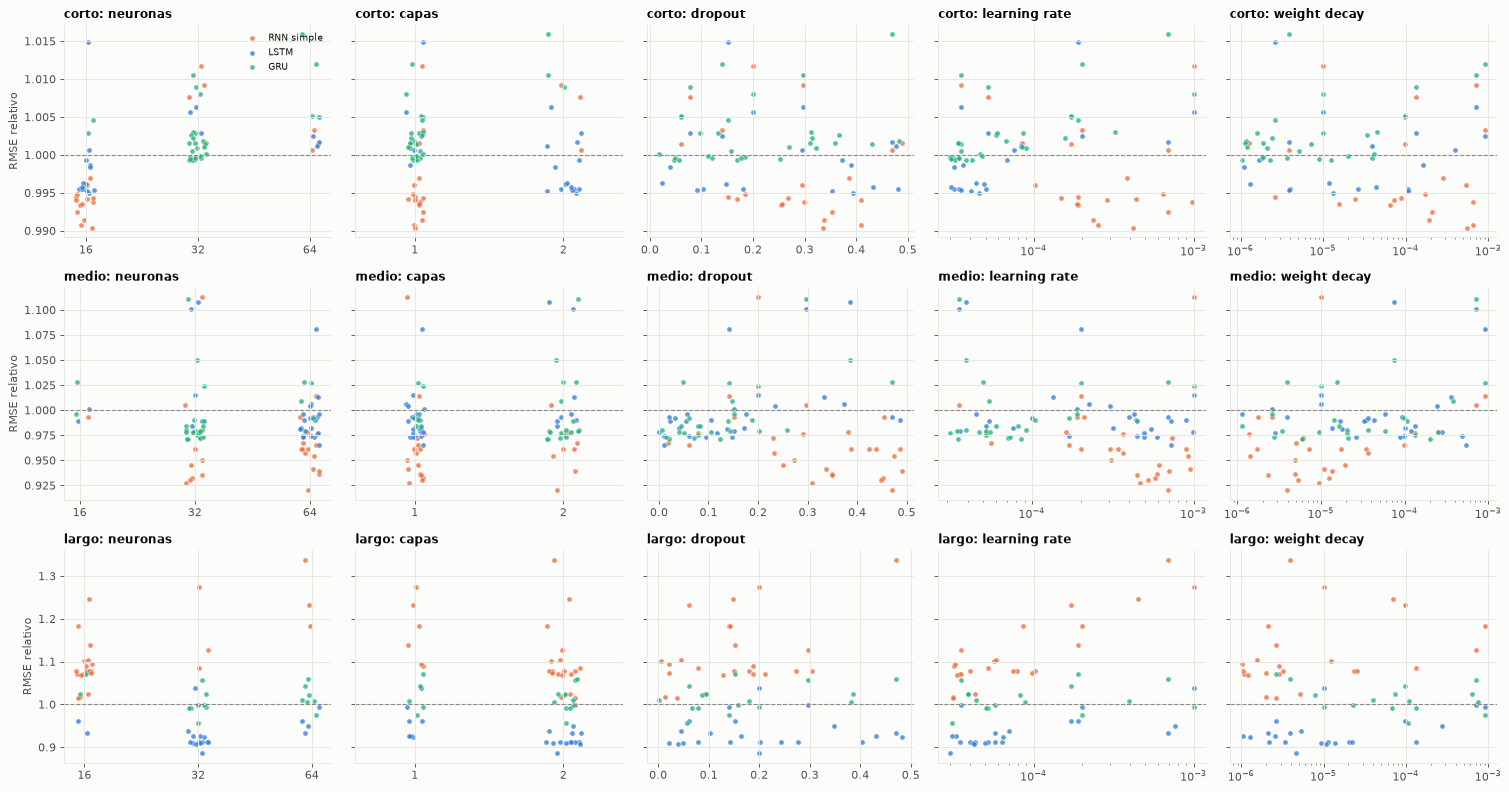

In [9]:
done = sel[sel.state == "COMPLETE"]
params = [("params_hidden_size", "neuronas", False), ("params_num_layers", "capas", False),
          ("params_dropout", "dropout", False), ("params_lr", "learning rate", True),
          ("params_weight_decay", "weight decay", True)]
fig, axes = plt.subplots(3, 5, figsize=(19, 10), sharey="row")
rng = np.random.default_rng(0)
for row, hname in zip(axes, HORIZONS):
    d = done[done.horizonte == hname]
    for ax, (col, label, log) in zip(row, params):
        for red in NETS:
            g = d[d.red == red]
            x = g[col].astype(float)
            if col in ("params_hidden_size", "params_num_layers"):
                x = x * (1 + rng.uniform(-0.06, 0.06, len(x)))
            ax.scatter(x, g["value"], s=22, color=COLORS[red], alpha=0.75, label=red, edgecolor="white", linewidth=0.5)
        ax.axhline(1, color=COLORS["Ingenuo"], ls="--", lw=1)
        if col == "params_hidden_size":
            ax.set_xscale("log", base=2); ax.set_xticks([16, 32, 64], ["16", "32", "64"])
            ax.xaxis.set_minor_formatter(NullFormatter())
        elif col == "params_num_layers":
            ax.set_xticks([1, 2]); ax.set_xlim(0.6, 2.4)
        elif log:
            ax.set_xscale("log"); ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(f"{hname}: {label}", fontsize=11)
    row[0].set_ylabel("RMSE relativo")
axes[0, 0].legend(loc="upper right", fontsize=8)
plt.tight_layout()

In [10]:
hp = ["params_hidden_size", "params_num_layers", "params_dropout", "params_lr", "params_weight_decay", "params_batch_size"]
corr = pd.DataFrame({hname: {c.replace("params_", ""): done[done.horizonte == hname][c].astype(float)
                                .corr(done[done.horizonte == hname]["value"], method="spearman") for c in hp}
                     for hname in HORIZONS})
loss = done.groupby(["horizonte", "params_loss"])["value"].median().unstack().loc[list(HORIZONS)]
display(Markdown("**Correlación de Spearman entre cada hiperparámetro y el error** (positiva: cuanto más alto, peor)"))
display(corr.style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-0.7, vmax=0.7))
display(Markdown("**Error mediano según la pérdida**"))
display(loss)

**Correlación de Spearman entre cada hiperparámetro y el error** (positiva: cuanto más alto, peor)

,corto,medio,largo
hidden_size,+0.70,-0.09,-0.30
num_layers,+0.04,+0.08,-0.13
dropout,-0.15,-0.09,-0.03
lr,+0.05,-0.28,+0.25
weight_decay,-0.06,+0.28,-0.05
batch_size,-0.03,-0.11,+0.46


**Error mediano según la pérdida**

params_loss,huber,mse
horizonte,,
corto,0.999,1.003
medio,0.978,1.050
largo,0.976,1.072


**Qué hiperparámetros funcionan:**
- **Pérdida de Huber:** a 3 meses su mediana es 0,978 frente a 1,050 con MSE, y a 1 año 0,976 frente a 1,072. Es la diferencia más clara del ajuste: con colas tan pesadas, una pérdida robusta evita que 2020 domine el entrenamiento.
- **El tamaño ideal depende del horizonte:** a 1 semana, cuantas más neuronas, peor (ρ = +0,70): no hay señal que aprender y una red grande solo memoriza ruido. A 1 año ayudan algo las redes más grandes (ρ = −0,30) con lotes pequeños.
- ***Learning rate*:** a 3 meses algo más alto ayuda (ρ = −0,28); a 1 año, mejor aprender despacio (ρ = +0,25).
- **Dropout y número de capas:** efecto pequeño en los tres horizontes.

## 8. Conclusiones

**Ranking en validación con la ventana de 20 días** (RMSE relativo al ingenuo; < 1 = mejor; mejor de 30 intentos con 2 semillas):

| Horizonte | 1º | 2º | 3º |
|---|---|---|---|
| 1 semana (5 d) | RNN simple 0,990 | LSTM 0,995 | GRU 0,999 |
| 3 meses (63 d) | **RNN simple 0,920** | LSTM 0,965 | GRU 0,971 |
| 1 año (252 d) | **LSTM 0,887** | GRU 0,957 | RNN simple 1,016 |

1. **A 1 semana ninguna red aporta:** todas convergen a «el precio no cambia», como predice la hipótesis de mercados eficientes y como recoge la literatura (Alquist, Kilian y Vigfusson, 2013).
2. **A 3 meses aparece señal:** las tres redes mejoran al ingenuo, y la RNN simple lo hace **todos los años de validación**.
3. **A 1 año el resultado depende de pocos episodios** (pandemia, rebote de 2021, guerra de Ucrania); la LSTM es la mejor, apoyada sobre todo en 2022.
4. **La celda más compleja no gana siempre:** la memoria larga de la LSTM solo compensa a 1 año; a 3 meses la RNN simple es mejor con menos parámetros.

> Estos valores son el **mejor de 30 intentos** sobre los mismos años, así que son algo optimistas. El notebook 08 vuelve a validar las ganadoras con 5 semillas, comprueba si su ventaja se sostiene en 2010-2018 y fija el modelo final; el notebook 07 lo evalúa en el test 2024-2026.